# Hybrid Bollywood Movie Recommendation System
**SPPU BE Computer Engineering — Machine Learning Mini-Project**

This notebook implements and explores:
1. Content-based filtering with TF-IDF + cosine similarity.
2. Item-based collaborative filtering from user ratings.
3. SVD matrix factorisation.
4. A weighted hybrid recommendation ranking.

Before running, download the datasets listed in `README.md` and place them under `data/`.

In [7]:
from pathlib import Path
import pandas as pd
import sys
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

from recommender import load_project_data, HybridBollywoodRecommender

DATA_DIR = Path(
    r"D:\bollywood_hybrid_recommender\bollywood_hybrid_recommender\data"
)
movies, ratings = load_project_data(DATA_DIR)

print("Movies:", movies.shape)
print("Mapped ratings:", ratings.shape)
print("Unique users:", ratings["user_id"].nunique())
display(movies.head())
display(ratings.head())

Movies: (4284, 22)
Mapped ratings: (17539, 3)
Unique users: 5651


,title_x,imdb_id,poster,wiki_link,title_y,title,is_adult,year,runtime,genres,...,story,overview,tagline,actors,wins_nominations,release_date,imdb_key,directors,content_text,movie_key
0,Uri: The Surgical Strike,tt8291224,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Uri:_The_Surgica...,Uri: The Surgical Strike,Uri: The Surgical Strike,0,2019,138,Action|Drama|War,...,Divided over five chapters the film chronicle...,Indian army special forces execute a covert op...,NaN,Vicky Kaushal|Paresh Rawal|Mohit Raina|Yami Ga...,4 wins,11 January 2019 (USA),8291224,,uri: the surgical strike action|drama|war vic...,8291224
1,Battalion 609,tt9472208,NaN,https://en.wikipedia.org/wiki/Battalion_609,Battalion 609,Battalion 609,0,2019,131,War,...,The story revolves around a cricket match betw...,The story of Battalion 609 revolves around a c...,NaN,Vicky Ahuja|Shoaib Ibrahim|Shrikant Kamat|Elen...,NaN,11 January 2019 (India),9472208,,battalion 609 war vicky ahuja|shoaib ibrahim|...,9472208
2,The Accidental Prime Minister (film),tt6986710,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/The_Accidental_P...,The Accidental Prime Minister,The Accidental Prime Minister,0,2019,112,Biography|Drama,...,Based on the memoir by Indian policy analyst S...,Explores Manmohan Singh's tenure as the Prime ...,NaN,Anupam Kher|Akshaye Khanna|Aahana Kumra|Atul S...,NaN,11 January 2019 (USA),6986710,,the accidental prime minister biography|drama ...,6986710
3,Why Cheat India,tt8108208,https://upload.wikimedia.org/wikipedia/en/thum...,https://en.wikipedia.org/wiki/Why_Cheat_India,Why Cheat India,Why Cheat India,0,2019,121,Crime|Drama,...,The movie focuses on existing malpractices in ...,The movie focuses on existing malpractices in ...,NaN,Emraan Hashmi|Shreya Dhanwanthary|Snighdadeep ...,NaN,18 January 2019 (USA),8108208,,why cheat india crime|drama emraan hashmi|shr...,8108208
4,Evening Shadows,tt6028796,NaN,https://en.wikipedia.org/wiki/Evening_Shadows,Evening Shadows,Evening Shadows,0,2018,102,Drama,...,While gay rights and marriage equality has bee...,Under the 'Evening Shadows' truth often plays...,NaN,Mona Ambegaonkar|Ananth Narayan Mahadevan|Deva...,17 wins & 1 nomination,11 January 2019 (India),6028796,,evening shadows drama mona ambegaonkar|ananth...,6028796


,user_id,movie_key,rating
0,172,1821480,5.0
1,172,2082197,4.0
2,176,1187043,4.0
3,221,118849,4.5
4,333,437407,4.0


## 1. Data quality checks

Missing values in selected metadata:


title         0
genres        0
overview      1
actors       10
directors     0
rating       13
dtype: int64

Duplicate titles: 237
Ratings distribution:


count    17539.000000
mean         3.466731
std          1.202661
min          0.500000
25%          3.000000
50%          3.500000
75%          4.500000
max          5.000000
Name: rating, dtype: float64

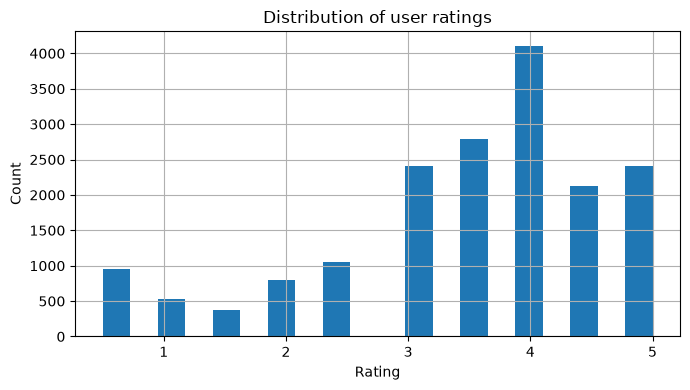

In [8]:
print("Missing values in selected metadata:")
display(movies[["title", "genres", "overview", "actors", "directors", "rating"]].isna().sum())

print("Duplicate titles:", movies["title"].duplicated().sum())
print("Ratings distribution:")
display(ratings["rating"].describe())

plt.figure(figsize=(7, 4))
ratings["rating"].hist(bins=20)
plt.title("Distribution of user ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 2. Train the three recommendation approaches

In [9]:
model = HybridBollywoodRecommender(movies, ratings)
print(f"Content feature matrix: {model.content_matrix.shape}")
print(f"Collaborative rating matrix: {None if model.rating_matrix is None else model.rating_matrix.shape}")
print("Mapped users:", len(model.user_ids))
print("Mapped rated movies:", len(model.item_keys))

Content feature matrix: (4284, 50000)
Collaborative rating matrix: (5651, 774)
Mapped users: 5651
Mapped rated movies: 774


## 3. Algorithm 1 — Content-based filtering

In [10]:
# Select an available title. You can replace this with any exact title from movies['title'].
seed_title = movies["title"].iloc[0]
print("Selected movie:", seed_title)
display(model.recommend_content(seed_title, n=10)[
    ["title", "year", "genres", "rating", "content_score"]
])

Selected movie: Uri: The Surgical Strike


,title,year,genres,rating,content_score
106,Raazi,2018,Action|Drama|Thriller,7.8,0.102220
352,Ki & Ka,2016,Comedy|Romance,5.8,0.089512
2143,Ek Hi Raasta,1993,Action|Thriller,3.5,0.082533
3005,Nakhuda,1981,Drama|Family|Romance,6.3,0.080310
1,Battalion 609,2019,War,4.1,0.078118
3500,Hindustan Ki Kasam,1973,Action|Drama|War,6.1,0.076443
376,Shamitabh,2015,Drama,6.8,0.074464
1763,China Gate,1998,Action|Adventure|Drama,6.6,0.074364
1894,Army,1996,Action|Drama,4.3,0.073943
1430,Dil Pardesi Ho Gayaa,2003,Drama|Romance,4.8,0.072187


TF-IDF weights informative words in each movie's combined metadata. Cosine similarity ranks films whose metadata vectors are close to the selected film.

## 4. Algorithm 2 — Item-based collaborative filtering

In [11]:
# Pick a user who has at least one mapped rating.
user_rating_counts = ratings.groupby("user_id").size().sort_values(ascending=False)
sample_user = str(user_rating_counts.index[0])
print("Example user ID:", sample_user)
display(
    ratings[ratings["user_id"] == sample_user]
    .merge(movies[["movie_key", "title"]], on="movie_key", how="left")
    .sort_values("rating", ascending=False)
    .head(15)
)

Example user ID: 190096


,user_id,movie_key,rating,title
2,190096,164538,5.0,Dil Se..
425,190096,1916728,5.0,Shor in the City
26,190096,367110,5.0,Swades: We the People
37,190096,72777,5.0,Chhoti Si Baat
328,190096,68257,5.0,Bawarchi
81,190096,2072227,5.0,Shanghai
313,190096,3019620,5.0,Titli
6,190096,292490,5.0,Dil Chahta Hai
450,190096,105271,5.0,Roja
19,190096,986264,5.0,Taare Zameen Par


The model compares movie rating vectors across users. For a user with a rating history, it uses the ratings of similar movies to generate a preference score.

In [12]:
item_recs = model.recommend_user(
    user_id=sample_user,
    seed_title=seed_title,
    n=10,
    content_weight=0.0,
    item_weight=1.0,
    svd_weight=0.0
)
display(item_recs[["title", "genres", "item_cf_score"]])

,title,genres,item_cf_score
898,No Problem,Action|Comedy|Crime,1.0
1557,The Legend of Bhagat Singh,Action|Biography|Drama,1.0
1299,Shabd,Drama,1.0
859,Raavan,Action|Adventure|Drama,1.0
314,Dishoom,Action|Adventure|Comedy,1.0
1327,Aitraaz,Drama|Romance|Thriller,1.0
1152,Bhagam Bhag,Comedy|Mystery|Thriller,1.0
971,De Dana Dan,Comedy|Crime,1.0
920,Ajab Prem Ki Ghazab Kahani,Action|Comedy|Romance,1.0
818,The Dirty Picture,Biography|Drama,1.0


## 5. Algorithm 3 — SVD matrix factorisation

In [13]:
svd_recs = model.recommend_user(
    user_id=sample_user,
    seed_title=None,
    n=10,
    content_weight=0.0,
    item_weight=0.0,
    svd_weight=1.0
)
display(svd_recs[["title", "genres", "svd_score"]])

,title,genres,svd_score
1914,Fire,Drama|Romance,0.686419
1227,Black,Drama,0.620446
776,Delhi Belly,Action|Comedy|Crime,0.589929
1557,The Legend of Bhagat Singh,Action|Biography|Drama,0.582142
859,Raavan,Action|Adventure|Drama,0.541323
279,Nil Battey Sannata,Drama|Family,0.538158
891,Guzaarish,Drama,0.537329
1080,Eklavya,Action|Drama|Thriller,0.534600
740,Dhobi Ghat,Drama,0.533417
4128,Mother India,Drama|Family|Musical,0.532665


SVD represents users and movies using lower-dimensional latent factors. In this educational implementation, missing ratings are filled with zero before factorisation; therefore, scores are approximate ranking signals rather than calibrated star-rating predictions. Discuss this limitation in your report.

## 6. Hybrid recommendation

In [14]:
hybrid_recs = model.recommend_user(
    user_id=sample_user,
    seed_title=seed_title,
    n=10,
    content_weight=0.4,
    item_weight=0.3,
    svd_weight=0.3
)
display(hybrid_recs[[
    "title", "year", "genres", "rating",
    "content_score", "item_cf_score", "svd_score", "hybrid_score"
]])

,title,year,genres,rating,content_score,item_cf_score,svd_score,hybrid_score
1914,Fire,1996,Drama|Romance,7.2,0.000754,1.0,0.686419,0.506227
1227,Black,2005,Drama,8.2,0.002083,1.0,0.620446,0.486967
1557,The Legend of Bhagat Singh,2002,Action|Biography|Drama,8.1,0.017203,1.0,0.582142,0.481524
776,Delhi Belly,2011,Action|Comedy|Crime,7.5,0.008934,1.0,0.589929,0.480552
352,Ki & Ka,2016,Comedy|Romance,5.8,0.089512,1.0,0.461310,0.474198
891,Guzaarish,2010,Drama,7.4,0.025794,1.0,0.537329,0.471516
898,No Problem,2010,Action|Comedy|Crime,4.2,0.022216,1.0,0.530397,0.468006
880,Khichdi: The Movie,2010,Comedy|Family,7.2,0.053554,1.0,0.480654,0.465618
1327,Aitraaz,2004,Drama|Romance|Thriller,6.6,0.028842,1.0,0.509141,0.464279
859,Raavan,2010,Action|Adventure|Drama,5.4,0.002583,1.0,0.541323,0.463430


## 7. Compare recommendation signals

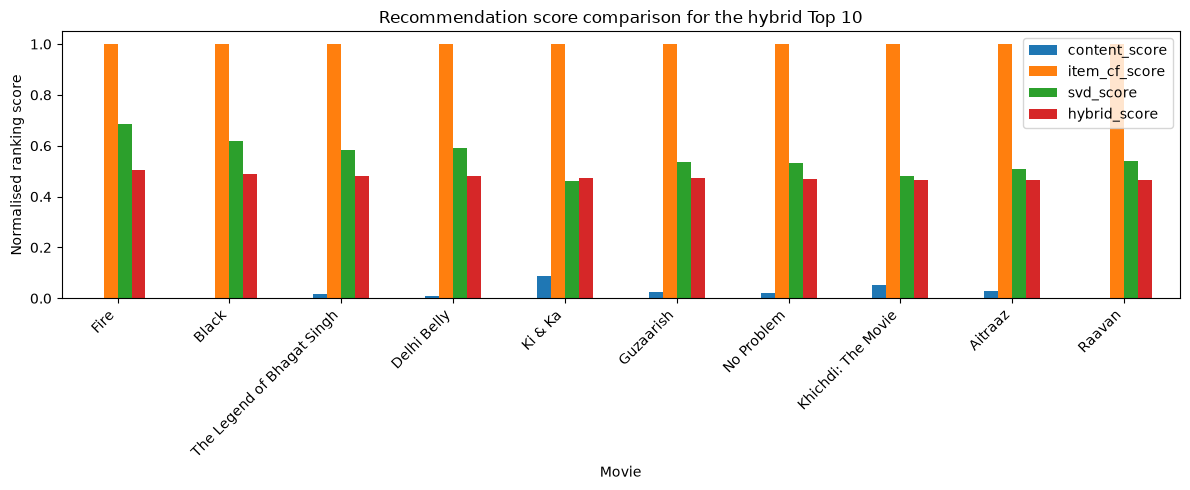

In [15]:
plot_df = hybrid_recs.set_index("title")[[
    "content_score", "item_cf_score", "svd_score", "hybrid_score"
]]
plot_df.plot(kind="bar", figsize=(12, 5))
plt.title("Recommendation score comparison for the hybrid Top 10")
plt.ylabel("Normalised ranking score")
plt.xlabel("Movie")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 8. Evaluation plan for the report

For a fair evaluation, split user ratings into train and test sets **before** building the collaborative models. Then compare:

- **Precision@K:** proportion of recommended Top-K movies judged relevant.
- **Recall@K:** proportion of held-out relevant movies recovered in Top-K.
- **NDCG@K:** ranking quality, rewarding relevant films near the top.
- **RMSE:** only if you implement and evaluate actual numerical rating predictions.

Do not calculate these metrics on the same ratings used to build the recommender; that creates data leakage and overstates performance. The present notebook is the implementation walkthrough; a held-out evaluation can be added as the next experiment once you confirm the dataset's mapped rating coverage.

## Conclusion

The project demonstrates three different recommendation approaches and combines their scores into a hybrid ranking. The main practical challenges are matching movie IDs correctly, rating sparsity, cold-start users, and evaluating recommendations on unseen interactions.